# Heatwave Prediction: From ML to MLflow to MLOps to DevOps
**Notebook:** `Heatwave_Prediction_MLOps.ipynb`

This single notebook runs all four lab experiments end to end:

1. **Machine Learning** — on the exact 20-row teaching dataset from the manual.
2. **MLflow** — experiment tracking, on a larger 3-year synthetic daily dataset (`heatwave_timeseries.csv`) so the tracking/comparison step has enough data to be meaningful.
3. **MLOps** — save the best MLflow run's model and expose it as a Flask prediction API.
4. **DevOps** — project structure, `Dockerfile`, and a GitHub Actions CI workflow (build/run outside Colab, using Docker Desktop + GitHub).

> Note on the Experiment 2-4 dataset: this environment could not reach an
> external dataset site directly, so a realistic 3-year synthetic daily
> weather record (seasonal temperature/humidity/wind curves + noise, with
> an IMD-style heatwave rule) was generated with the same column names as
> the manual's dataset. Swap in a real IMD/Kaggle CSV with identical
> column names and every downstream cell works unchanged.


## Part A — Machine Learning (Experiment 1)

### Step 1-2: Install packages

In [1]:
!pip install -q mlflow scikit-learn pandas matplotlib seaborn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

### Step 3: Create the teaching dataset (exactly as given in the manual)

In [2]:
import pandas as pd

data = pd.DataFrame({
    "max_temp":[38,40,43,45,36,42,39,44,41,46,37,43,45,39,41,47,38,44,42,46],
    "min_temp":[27,28,30,31,26,29,27,30,28,32,26,30,31,27,29,33,27,31,29,32],
    "humidity":[65,60,55,50,70,58,68,52,62,48,72,56,49,66,59,45,69,51,57,47],
    "wind_speed":[12,10,8,7,15,9,11,8,10,6,14,8,7,12,9,5,13,7,9,6],
    "previous_temp":[37,39,42,44,35,41,38,43,40,45,36,42,44,38,40,46,37,43,41,45],
    "heatwave":[0,0,1,1,0,1,0,1,0,1,0,1,1,0,0,1,0,1,1,1]
})
data.head()


,max_temp,min_temp,humidity,wind_speed,previous_temp,heatwave
0,38,27,65,12,37,0
1,40,28,60,10,39,0
2,43,30,55,8,42,1
3,45,31,50,7,44,1
4,36,26,70,15,35,0


### Step 4: Explore the data

In [3]:
data.info()
print(data.describe())
print(data.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   max_temp       20 non-null     int64
 1   min_temp       20 non-null     int64
 2   humidity       20 non-null     int64
 3   wind_speed     20 non-null     int64
 4   previous_temp  20 non-null     int64
 5   heatwave       20 non-null     int64
dtypes: int64(6)
memory usage: 1.1 KB
        max_temp   min_temp   humidity  wind_speed  previous_temp   heatwave
count  20.000000  20.000000  20.000000   20.000000      20.000000  20.000000
mean   41.800000  29.150000  57.950000    9.300000      40.800000   0.550000
std     3.254147   2.109502   8.363297    2.792848       3.254147   0.510418
min    36.000000  26.000000  45.000000    5.000000      35.000000   0.000000
25%    39.000000  27.000000  50.750000    7.000000      38.000000   0.000000
50%    42.000000  29.000000  57.500000    9.000000      41.000000   1.000

### Step 5-6: Features/target, train-test split

In [4]:
from sklearn.model_selection import train_test_split

X = data[["max_temp","min_temp","humidity","wind_speed","previous_temp"]]
y = data["heatwave"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Step 7-8: Train, predict, evaluate

Accuracy: 1.0


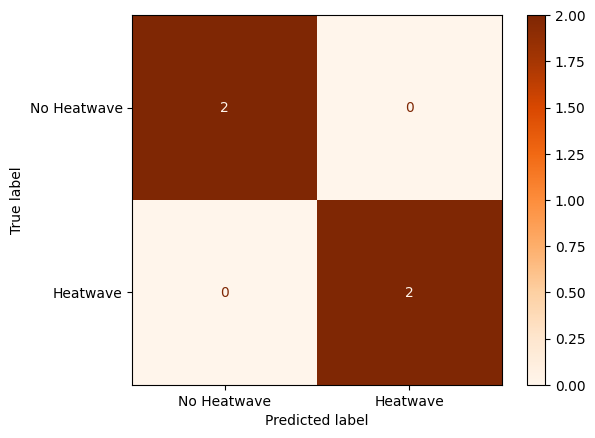

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                        display_labels=["No Heatwave","Heatwave"]).plot(cmap="Oranges")


**Learning checkpoint:** a working ML model. This completes the ML stage (Experiment 1).

## Part B — MLflow (Experiment 2)
From here on we switch to the larger, more realistic dataset described in the note above.


### Load the Experiment 2-4 dataset

In [6]:
# In your own Colab: replace this cell with a real dataset download
# (e.g. `!wget <dataset-url> -O heatwave_timeseries.csv`) using the same
# column names, then continue unchanged.
ts = pd.read_csv("heatwave_timeseries.csv", parse_dates=["date"])
print(ts.shape)
ts.head()


(1095, 7)


,date,max_temp,min_temp,humidity,wind_speed,previous_temp,heatwave
0,2022-01-01,17.1,8.0,88.7,12.8,17.1,0
1,2022-01-02,17.7,10.0,84.1,13.8,16.7,0
2,2022-01-03,16.5,8.0,89.4,13.1,18.6,0
3,2022-01-04,15.1,8.0,98.0,18.4,16.0,0
4,2022-01-05,16.0,9.7,85.1,18.6,14.6,0


In [7]:
Xt = ts[["max_temp","min_temp","humidity","wind_speed","previous_temp"]]
yt = ts["heatwave"]
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    Xt, yt, test_size=0.2, random_state=42, stratify=yt)


> **Note:** on current MLflow releases, `mlflow.sklearn.log_model()` defaults to the `skops` format, which refuses to serialize a `RandomForestClassifier` unless you either pass `serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE` (used below) or explicitly trust `sklearn.tree._tree.Tree`. If your MLflow version does not raise this, you can drop the extra argument.

### Step 9-11: MLflow experiment + a tracked run

In [8]:
import mlflow, mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///mlflow.db")   # use a local server URI in your own Colab
mlflow.set_experiment("Heatwave Prediction")

with mlflow.start_run():
    n_estimators, max_depth = 100, 5
    m = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
    m.fit(Xt_train, yt_train)
    pred = m.predict(Xt_test)
    acc = accuracy_score(yt_test, pred)
    mlflow.log_param("n_estimators", n_estimators)
    mlflow.log_param("max_depth", max_depth)
    mlflow.log_metric("accuracy", acc)
    mlflow.sklearn.log_model(m, "heatwave_model", serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)
    print("Accuracy:", acc)


2026/09/16 22:28:52 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/16 22:28:52 INFO mlflow.store.db.utils: Updating database tables


2026/09/16 22:28:53 INFO mlflow.tracking.fluent: Experiment with name 'Heatwave Prediction' does not exist. Creating a new experiment.


2026/09/16 22:28:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/09/16 22:28:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Accuracy: 0.9360730593607306


### Step 12: Run three experiments and compare

In [9]:
from sklearn.metrics import classification_report

runs_config = [
    {"n_estimators": 50,  "max_depth": 3},
    {"n_estimators": 100, "max_depth": 5},
    {"n_estimators": 200, "max_depth": 10},
]

run_results = []
for cfg in runs_config:
    with mlflow.start_run(run_name=f"rf_n{cfg['n_estimators']}_d{cfg['max_depth']}") as run:
        m = RandomForestClassifier(random_state=42, **cfg)
        m.fit(Xt_train, yt_train)
        pred = m.predict(Xt_test)
        acc = accuracy_score(yt_test, pred)
        report = classification_report(yt_test, pred, output_dict=True, zero_division=0)
        mlflow.log_param("n_estimators", cfg["n_estimators"])
        mlflow.log_param("max_depth", cfg["max_depth"])
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("f1_heatwave", report["1"]["f1-score"])
        mlflow.sklearn.log_model(m, "heatwave_model", serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_PICKLE)
        run_results.append({"run_name": f"n{cfg['n_estimators']}_d{cfg['max_depth']}",
                             **cfg, "accuracy": acc, "f1_heatwave": report["1"]["f1-score"], "model": m})
        print(cfg, "accuracy:", acc, "f1(heatwave):", report["1"]["f1-score"])

runs_df = pd.DataFrame([{k:v for k,v in r.items() if k != "model"} for r in run_results])
runs_df


2026/09/16 22:28:56 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/09/16 22:28:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/09/16 22:28:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/09/16 22:28:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


{'n_estimators': 50, 'max_depth': 3} accuracy: 0.9406392694063926 f1(heatwave): 0.6285714285714286


{'n_estimators': 100, 'max_depth': 5} accuracy: 0.9360730593607306 f1(heatwave): 0.6111111111111112


2026/09/16 22:29:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/09/16 22:29:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


{'n_estimators': 200, 'max_depth': 10} accuracy: 0.9406392694063926 f1(heatwave): 0.6829268292682927


,run_name,n_estimators,max_depth,accuracy,f1_heatwave
0,n50_d3,50,3,0.940639,0.628571
1,n100_d5,100,5,0.936073,0.611111
2,n200_d10,200,10,0.940639,0.682927


### Step 13-14: View and compare runs in the MLflow UI

In Colab: `!mlflow ui --port 5000` (tunnel with ngrok) or run `mlflow server --host 0.0.0.0 --port 5000` and open the Experiments page for **Heatwave Prediction** to compare parameters/metrics visually. The chart below is generated straight from the tracked run data as a stand-in:

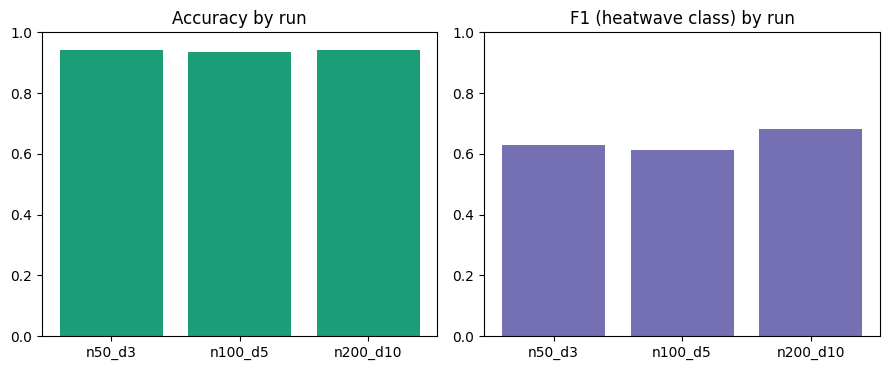

Best run: n200_d10


In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9,3.8))
axes[0].bar(runs_df["run_name"], runs_df["accuracy"], color="#1b9e77")
axes[0].set_title("Accuracy by run"); axes[0].set_ylim(0,1)
axes[1].bar(runs_df["run_name"], runs_df["f1_heatwave"], color="#7570b3")
axes[1].set_title("F1 (heatwave class) by run"); axes[1].set_ylim(0,1)
plt.tight_layout(); plt.show()

best = max(run_results, key=lambda r: r["f1_heatwave"])
best_model = best["model"]
print("Best run:", best["run_name"])


**Learning checkpoint:** MLflow adds experiment tracking and model-management capabilities.

## Part C — MLOps (Experiment 3)

### Step 15-16: Save the best model, prediction function

In [11]:
import joblib

joblib.dump(best_model, "heatwave_model.pkl")

def predict_heatwave(max_temp, min_temp, humidity, wind_speed, previous_temp):
    input_data = [[max_temp, min_temp, humidity, wind_speed, previous_temp]]
    prediction = best_model.predict(input_data)
    return "Heatwave" if prediction[0] == 1 else "No Heatwave"

print(predict_heatwave(45, 31, 50, 7, 44))


Heatwave


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


### Step 17: Expose the model as a Flask API

Save this as `app.py` (running a Flask server directly inside a notebook cell blocks execution, so this stage is normally run as a `.py` script):

In [12]:
app_py = """
from flask import Flask, request, jsonify
import joblib

app = Flask(__name__)
model = joblib.load("heatwave_model.pkl")

@app.route("/predict", methods=["POST"])
def predict():
    data = request.json
    features = [[data["max_temp"], data["min_temp"], data["humidity"],
                 data["wind_speed"], data["previous_temp"]]]
    prediction = model.predict(features)[0]
    return jsonify({"prediction": "Heatwave" if prediction == 1 else "No Heatwave"})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=8000)
"""
with open("app.py", "w") as f:
    f.write(app_py)
print("app.py written")


app.py written


Run it with `!python app.py &` then test with:

`!curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" -d '{"max_temp":45,"min_temp":31,"humidity":50,"wind_speed":7,"previous_temp":44}'`

**Learning checkpoint:** the trained model is packaged as a prediction service. This completes the MLOps stage.

## Part D — DevOps (Experiment 4)

Docker and GitHub Actions run outside the notebook. Project layout:

```
heatwave-mlops/
├── data/heatwave_data.csv
├── model/heatwave_model.pkl
├── app.py
├── train.py
├── requirements.txt
├── Dockerfile
└── .github/workflows/ci.yml
```

Build and run:
```bash
docker build -t heatwave-api:1.0 .
docker run -p 8000:8000 heatwave-api:1.0
```

Push to GitHub with the `heatwave-mlops` repo name; the CI workflow in
`.github/workflows/ci.yml` installs dependencies and compiles/tests the app
on every push to `main`.


**Learning checkpoint:** CI/CD-ready, containerized prediction service. This completes the DevOps stage.